# METABRIC PCA and k-means sensitivity analysis

This notebook extends [Sydney Shimizu’s exploratory PCA and k-means notebook](../SS_707_exploratory_PCA_kmeans_complete.ipynb). It evaluates all 45 combinations of 2–10 clusters and 20, 40, 60, 80, or 100 principal components from METABRIC gene expression.

In [1]:
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, silhouette_score
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits

DATA_DIR = Path("/Users/danielbility/Documents/brca/brca_metabric")
PC_COUNTS = (20, 40, 60, 80, 100)
K_VALUES = range(2, 11)
N_INIT = 20
BASE_SEED = 42
SILHOUETTE_SAMPLE_SIZE = 1000
N_RESAMPLES = 20
SUBSAMPLE_FRACTION = 0.80

print(f"Grid size  {len(PC_COUNTS) * len(K_VALUES)} combinations")
print(f"NumPy {np.__version__}  •  pandas {pd.__version__}  •  "
      f"scikit-learn {sklearn.__version__}  •  Matplotlib {mpl.__version__}")

Grid size  45 combinations
NumPy 2.3.5  •  pandas 2.2.3  •  scikit-learn 1.9.1  •  Matplotlib 3.11.2


## Load expression data and align subtype labels

Sydney used mRNA expression z-scores relative to diploid samples. Duplicate gene symbols are averaged, and clinical labels are aligned to the expression matrix by sample ID. The five standard PAM50 groups are mapped from `CLAUDIN_SUBTYPE` for the NMI calculation. All expression samples enter clustering, silhouette, and stability.

In [2]:
expression_by_gene = pd.read_csv(
    DATA_DIR / "data_mrna_illumina_microarray_zscores_ref_diploid_samples.txt",
    sep="\t",
    index_col="Hugo_Symbol",
)
expression = (
    expression_by_gene.drop(columns="Entrez_Gene_Id", errors="ignore")
    .groupby(level=0).mean()
    .T.rename_axis("SAMPLE_ID")
)
del expression_by_gene

patients = pd.read_csv(
    DATA_DIR / "data_clinical_patient.txt",
    sep="\t",
    comment="#",
    usecols=["PATIENT_ID", "CLAUDIN_SUBTYPE"],
)
samples = pd.read_csv(
    DATA_DIR / "data_clinical_sample.txt",
    sep="\t",
    comment="#",
    usecols=["PATIENT_ID", "SAMPLE_ID"],
)
subtypes_by_sample = (
    patients.merge(samples, on="PATIENT_ID", validate="one_to_many")
    .set_index("SAMPLE_ID", verify_integrity=True)["CLAUDIN_SUBTYPE"]
)
raw_subtypes = subtypes_by_sample.reindex(expression.index).astype("string").str.strip()

pam50_map = {
    "LUMA": "Luminal A",
    "LUMINAL A": "Luminal A",
    "LUMB": "Luminal B",
    "LUMINAL B": "Luminal B",
    "HER2": "HER2-enriched",
    "HER2-ENRICHED": "HER2-enriched",
    "HER2 ENRICHED": "HER2-enriched",
    "BASAL": "Basal-like",
    "BASAL-LIKE": "Basal-like",
    "NORMAL": "Normal-like",
    "NORMAL-LIKE": "Normal-like",
}

pam50_labels = raw_subtypes.str.upper().map(pam50_map)
known_pam50 = pam50_labels.notna().to_numpy()
pam50_reference = pam50_labels.to_numpy(dtype=str, na_value="")[known_pam50]

print(f"Expression matrix  {expression.shape[0]:,} samples × {expression.shape[1]:,} genes")
print(f"Samples included in NMI  {known_pam50.sum():,} of {len(known_pam50):,}")
display(pam50_labels.fillna("Other or missing").value_counts().rename("Samples").to_frame())

Expression matrix  1,980 samples × 20,385 genes
Samples included in NMI  1,756 of 1,980


,Samples
CLAUDIN_SUBTYPE,
Luminal A,700
Luminal B,475
HER2-enriched,224
Other or missing,224
Basal-like,209
Normal-like,148


## Filter genes and fit PCA

Sydney’s MAD filter excludes genes with more than 10% missingness or zero variance, then retains up to 2,000 genes with the highest median absolute deviation. The selected genes are median-imputed and standardized. A single 100-component randomized PCA fit supplies nested prefixes of unwhitened scores for all five PC counts.

In [3]:
import warnings
import numpy as np
from sklearn.base import BaseEstimator, TransformerMixin

# Gene selection settings
MAX_GENE_MISSING = 0.10   # Exclude genes missing in more than 10% of samples
N_TOP_MAD_GENES = 2000    # Keep up to 2,000 genes with the highest MAD


def nan_mad(A):
    """Calculate each gene's median absolute deviation, ignoring missing values."""
    A = np.asarray(A, dtype=float)
    out = np.empty(A.shape[1])
    has_nan = np.isnan(A).any(axis=0)

    full = A[:, ~has_nan]
    out[~has_nan] = np.median(
        np.abs(full - np.median(full, axis=0)),
        axis=0
    )

    if has_nan.any():
        part = A[:, has_nan]
        out[has_nan] = np.nanmedian(
            np.abs(part - np.nanmedian(part, axis=0)),
            axis=0
        )

    return out


class MADGeneFilter(TransformerMixin, BaseEstimator):
    """Filter genes by missingness and variability, then keep the highest-MAD genes."""

    def __init__(self, max_missing=0.10, n_genes=2000):
        self.max_missing = max_missing
        self.n_genes = n_genes

    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        self.n_features_in_ = X.shape[1]

        # Step 1: exclude genes with too much missing data.
        passes_missing = np.isnan(X).mean(axis=0) <= self.max_missing

        # Step 2: exclude genes with no variation.
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", category=RuntimeWarning)
            spread = np.nanmax(X, axis=0) - np.nanmin(X, axis=0)

        passes_variance = passes_missing & (spread > 0)

        # Step 3: rank remaining genes by median absolute deviation.
        self.mad_ = np.full(X.shape[1], -np.inf)
        self.mad_[passes_variance] = nan_mad(X[:, passes_variance])
        ranking = np.argsort(-self.mad_, kind="stable")

        # Step 4: keep up to the requested number of genes.
        n_keep = min(self.n_genes, int(passes_variance.sum()))
        self.keep_idx_ = np.sort(ranking[:n_keep])

        self.n_genes_start_ = X.shape[1]
        self.n_after_step1_ = int(passes_missing.sum())
        self.n_after_step2_ = int(passes_variance.sum())
        self.mad_cutoff_ = (
            float(self.mad_[ranking[n_keep - 1]]) if n_keep else float("nan")
        )

        return self

    def transform(self, X):
        return np.asarray(X, dtype=float)[:, self.keep_idx_]

    def get_feature_names_out(self, input_features=None):
        if input_features is None:
            raise ValueError("Pass input gene names to get_feature_names_out().")
        return np.asarray(input_features, dtype=object)[self.keep_idx_]

gene_filter = MADGeneFilter(max_missing=MAX_GENE_MISSING, n_genes=N_TOP_MAD_GENES)
selected_expression = gene_filter.fit_transform(expression)

print(f"Genes at start  {gene_filter.n_genes_start_:,}")
print(f"After missingness filter  {gene_filter.n_after_step1_:,}")
print(f"After zero-variance filter  {gene_filter.n_after_step2_:,}")
print(f"Genes selected  {selected_expression.shape[1]:,}")

Genes at start  20,385
After missingness filter  20,385
After zero-variance filter  20,385
Genes selected  2,000


In [4]:
expression_imputed = SimpleImputer(strategy="median").fit_transform(selected_expression)
expression_scaled = StandardScaler().fit_transform(expression_imputed)

pca = PCA(n_components=max(PC_COUNTS), svd_solver="randomized", random_state=0)
with threadpool_limits(limits=2):
    pc_scores = pca.fit_transform(expression_scaled)

variance_explained = np.cumsum(pca.explained_variance_ratio_)
display(pd.DataFrame({
    "Number of PCs": PC_COUNTS,
    "Cumulative variance explained": [f"{variance_explained[n - 1]:.2%}" for n in PC_COUNTS],
}).set_index("Number of PCs"))

,Cumulative variance explained
Number of PCs,
20,47.15%
40,55.26%
60,60.08%
80,63.34%
100,65.84%


## Score all 45 combinations

Each full-data k-means fit uses 20 initializations with seed 42.

- **Silhouette** uses Euclidean distances on Sydney’s seeded subset of up to 1,000 expression samples.
- **Stability ARI** averages 20 adjusted Rand indices. Each refit uses an 80% sample drawn without replacement and predicts clusters for all expression samples. Those predictions are compared with the full-data assignments. The same subsample indices are reused across the grid, with PCA and gene preprocessing held fixed.
- **NMI** compares full-data cluster assignments with the five mapped PAM50 groups on samples with a known mapped label. It uses arithmetic normalization.

In [5]:
rng = np.random.default_rng(0)
n_samples = pc_scores.shape[0]
subsamples = [
    rng.choice(n_samples, int(SUBSAMPLE_FRACTION * n_samples), replace=False)
    for _ in range(N_RESAMPLES)
]

rows = []
with threadpool_limits(limits=2):
    for n_pcs in PC_COUNTS:
        scores = np.ascontiguousarray(pc_scores[:, :n_pcs])
        for k in K_VALUES:
            clusters = KMeans(n_clusters=k, n_init=N_INIT, random_state=BASE_SEED).fit_predict(scores)
            silhouette = silhouette_score(
                scores,
                clusters,
                sample_size=min(SILHOUETTE_SAMPLE_SIZE, n_samples),
                random_state=BASE_SEED,
            )

            stability_scores = []
            for seed, indices in enumerate(subsamples):
                model = KMeans(n_clusters=k, n_init=N_INIT, random_state=seed)
                model.fit(scores[indices])
                stability_scores.append(adjusted_rand_score(clusters, model.predict(scores)))

            rows.append({
                "n_pcs": n_pcs,
                "k": k,
                "Silhouette": silhouette,
                "Stability ARI": np.mean(stability_scores),
                "NMI": normalized_mutual_info_score(
                    pam50_reference, clusters[known_pam50], average_method="arithmetic"
                ),
            })
        print(f"Finished {n_pcs:>3} PCs  •  {len(rows):>2}/{len(PC_COUNTS) * len(K_VALUES)} combinations")

results = pd.DataFrame(rows)
metrics = ["Silhouette", "Stability ARI", "NMI"]
expected_grid = pd.MultiIndex.from_product([PC_COUNTS, K_VALUES], names=["n_pcs", "k"])
assert results.set_index(["n_pcs", "k"]).index.equals(expected_grid)
assert np.isfinite(results[metrics].to_numpy()).all()

with pd.option_context("display.max_rows", len(results)):
    display(results.set_index(["n_pcs", "k"]).round(4))

Finished  20 PCs  •   9/45 combinations


Finished  40 PCs  •  18/45 combinations


Finished  60 PCs  •  27/45 combinations


Finished  80 PCs  •  36/45 combinations


Finished 100 PCs  •  45/45 combinations


Silhouette  Stability ARI     NMI
n_pcs k                                    
20    2       0.1584         0.9698  0.2832
      3       0.1327         0.9636  0.2630
      4       0.1261         0.8548  0.2486
      5       0.1135         0.8414  0.3061
      6       0.1073         0.7852  0.3355
      7       0.1032         0.8515  0.3263
      8       0.1040         0.9187  0.3195
      9       0.0989         0.8265  0.3049
      10      0.0961         0.6839  0.3006
40    2       0.1352         0.9698  0.2841
      3       0.1114         0.9605  0.2664
      4       0.1054         0.8701  0.2484
      5       0.0939         0.8543  0.3070
      6       0.0835         0.7675  0.3230
      7       0.0824         0.8698  0.3182
      8       0.0836         0.9056  0.3178
      9       0.0783         0.8337  0.3082
      10      0.0816         0.6976  0.3027
60    2       0.1243         0.9687  0.2837
      3       0.1007         0.9593  0.2650
      4       0.0950         0.8552  0.2490
      5       0.0847         0.8381  0.3069
      6       0.0724         0.7790  0.3133
      7       0.0726         0.8683  0.3199
      8       0.0734         0.9075  0.3170
      9       0.0679         0.8105  0.3155
      10      0.0699         0.6660  0.3144
80    2       0.1181         0.9704  0.2835
      3       0.0944         0.9590  0.2655
      4       0.0898         0.8703  0.2486
      5       0.0798         0.8405  0.3081
      6       0.0692         0.7865  0.3248
      7       0.0668         0.8566  0.3234
      8       0.0677         0.9045  0.3175
      9       0.0617         0.7547  0.3063
      10      0.0600         0.6287  0.3005
100   2       0.1140         0.9706  0.2835
      3       0.0896         0.9602  0.2638
      4       0.0854         0.8767  0.2486
      5       0.0758         0.8642  0.3065
      6       0.0678         0.7466  0.3305
      7       0.0625         0.8628  0.3234
      8       0.0633         0.9055  0.3174
      9       0.0571         0.8009  0.3129
      10      0.0567         0.7103  0.3062

In [6]:
best_by_metric = pd.DataFrame(
    [
        (metric, int(row.n_pcs), int(row.k), row[metric])
        for metric in metrics
        for _, row in results.loc[results[metric].eq(results[metric].max())].iterrows()
    ],
    columns=["Measure", "Number of PCs", "k", "Grid maximum"],
)
display(best_by_metric.set_index("Measure").round({"Grid maximum": 4}))

,Number of PCs,k,Grid maximum
Measure,,,
Silhouette,20,2,0.1584
Stability ARI,100,2,0.9706
NMI,20,6,0.3355


## Compare metrics across k

Each panel shows one measure. Each line fixes the number of PCs while varying the number of clusters.

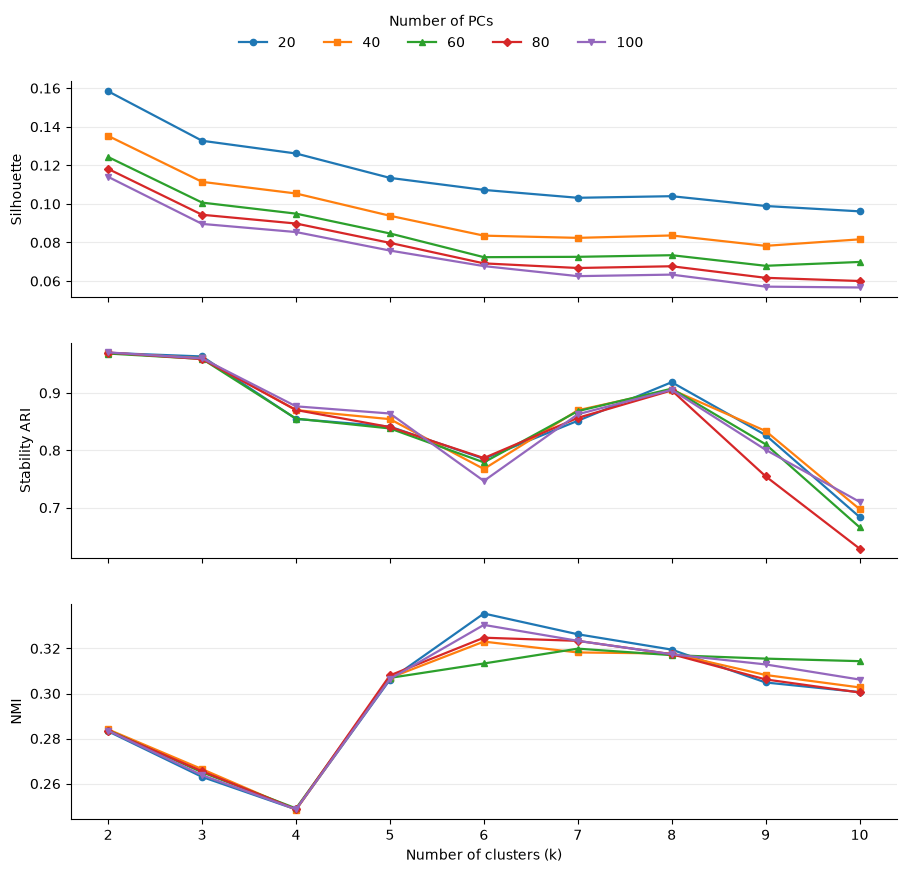

In [7]:
def plot_metric_profiles(x_col, x_values, x_label, series_col, series_values, legend_title):
    fig, axes = plt.subplots(3, 1, sharex=True, figsize=(9.5, 9))
    colors = plt.get_cmap("tab10").colors
    markers = ("o", "s", "^", "D", "v", "P", "X", "<", ">")

    for ax, metric in zip(axes, metrics):
        for value, color, marker in zip(series_values, colors, markers):
            profile = results.loc[results[series_col].eq(value)].sort_values(x_col)
            ax.plot(
                profile[x_col], profile[metric], label=str(value),
                color=color, marker=marker, linewidth=1.6, markersize=4.5,
            )
        ax.set_ylabel(metric)
        ax.grid(axis="y", alpha=0.25)
        ax.spines[["top", "right"]].set_visible(False)

    axes[-1].set_xticks(list(x_values))
    axes[-1].set_xlabel(x_label)
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(
        handles, labels, title=legend_title, ncol=len(labels),
        loc="upper center", bbox_to_anchor=(0.5, 0.988), frameon=False,
    )
    fig.subplots_adjust(left=0.11, right=0.98, top=0.9, bottom=0.08, hspace=0.21)
    plt.show()


plot_metric_profiles(
    x_col="k", x_values=K_VALUES, x_label="Number of clusters (k)",
    series_col="n_pcs", series_values=PC_COUNTS, legend_title="Number of PCs",
)

## Compare metrics across PC counts

Each line fixes k while varying the number of PCs.

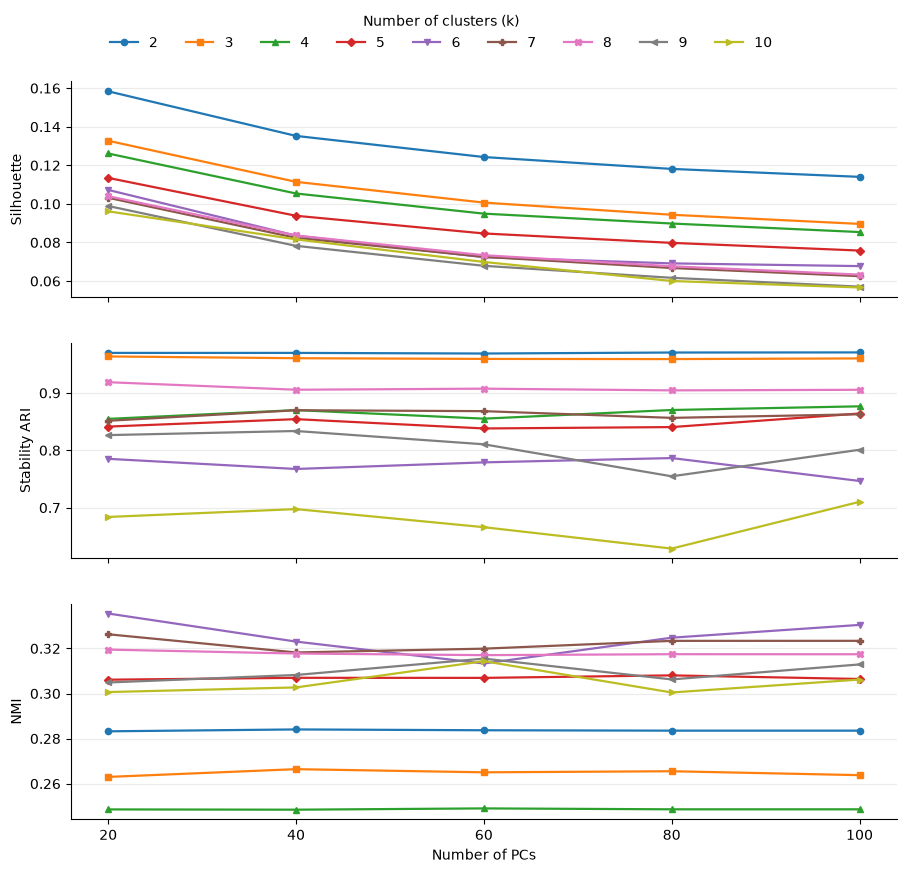

In [8]:
plot_metric_profiles(
    x_col="n_pcs", x_values=PC_COUNTS, x_label="Number of PCs",
    series_col="k", series_values=K_VALUES, legend_title="Number of clusters (k)",
)